(512, 512)


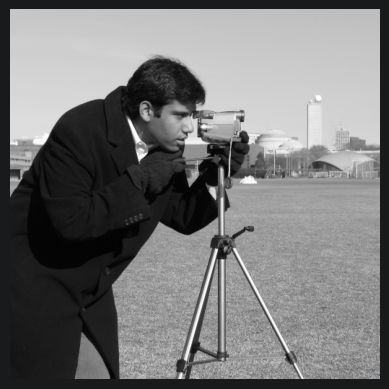

In [62]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data
import cv2 as cv
image = data.camera().astype(np.float64)
plt.imshow(image, cmap='gray')
plt.axis('off')
print(image.shape)

# Функции прямого и обратного вейвлет-преобразования Хаара

In [63]:
def haar2d_level(image):
    col_low = (image[:, 0::2] + image[:, 1::2]) / np.sqrt(2)   # L
    col_high = (image[:, 0::2] - image[:, 1::2]) / np.sqrt(2)  # H

    LL = (col_low[0::2, :] + col_low[1::2, :]) / np.sqrt(2)
    HL = (col_low[0::2, :] - col_low[1::2, :]) / np.sqrt(2)
    LH = (col_high[0::2, :] + col_high[1::2, :]) / np.sqrt(2)
    HH = (col_high[0::2, :] - col_high[1::2, :]) / np.sqrt(2)

    return LL, LH, HL, HH


def ihaar2d_level(LL, LH, HL, HH):
    col_low = np.zeros((LL.shape[0] * 2, LL.shape[1]), dtype=np.float64)
    col_low[0::2, :] = (LL + HL) / np.sqrt(2)
    col_low[1::2, :] = (LL - HL) / np.sqrt(2)

    col_high = np.zeros_like(col_low)
    col_high[0::2, :] = (LH + HH) / np.sqrt(2)
    col_high[1::2, :] = (LH - HH) / np.sqrt(2)

    reconstructed = np.zeros((col_low.shape[0], col_low.shape[1] * 2), dtype=np.float64)
    reconstructed[:, 0::2] = (col_low + col_high) / np.sqrt(2)
    reconstructed[:, 1::2] = (col_low - col_high) / np.sqrt(2)

    return reconstructed

# 3-уровневое разложение и сборка матрицы коэффициентов

In [64]:
# 1 уровень разложения (512x512 -> 4 субполосы по 256x256)
LL1, LH1, HL1, HH1 = haar2d_level(image)

# 2 уровень разложения (256x256 -> 4 субполосы по 128x128)
LL2, LH2, HL2, HH2 = haar2d_level(LL1)

# 3 уровень разложения (128x128 -> 4 субполосы по 64x64)
LL3, LH3, HL3, HH3 = haar2d_level(LL2)

print("Размерности поддиапазонов:")
print("Уровень 1:", LL1.shape, LH1.shape, HL1.shape, HH1.shape)
print("Уровень 2:", LL2.shape, LH2.shape, HL2.shape, HH2.shape)
print("Уровень 3:", LL3.shape, LH3.shape, HL3.shape, HH3.shape)

coeffs = np.zeros_like(image)

# Размещение уровней 1, 2 и 3
coeffs[0:256, 256:512] = LH1
coeffs[256:512, 0:256] = HL1
coeffs[256:512, 256:512] = HH1

coeffs[0:128, 128:256] = LH2
coeffs[128:256, 0:128] = HL2
coeffs[128:256, 128:256] = HH2

coeffs[0:64, 64:128] = LH3
coeffs[64:128, 0:64] = HL3
coeffs[64:128, 64:128] = HH3

coeffs[0:64, 0:64] = LL3

Размерности поддиапазонов:
Уровень 1: (256, 256) (256, 256) (256, 256) (256, 256)
Уровень 2: (128, 128) (128, 128) (128, 128) (128, 128)
Уровень 3: (64, 64) (64, 64) (64, 64) (64, 64)


# Визуализация вейвлет-коэффициентов и сглаживания

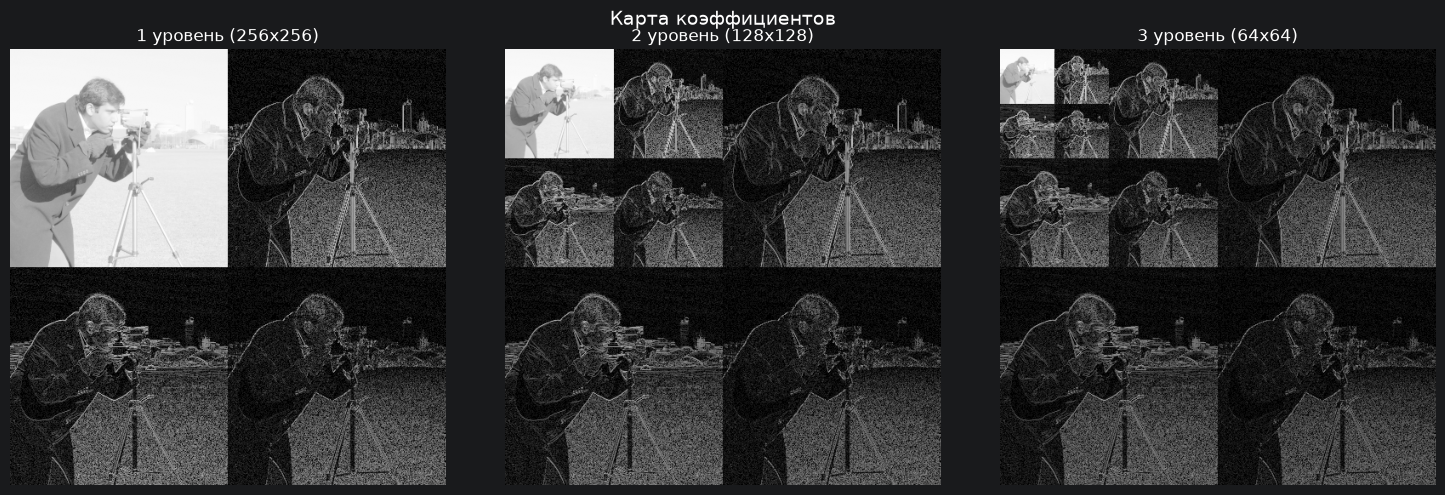

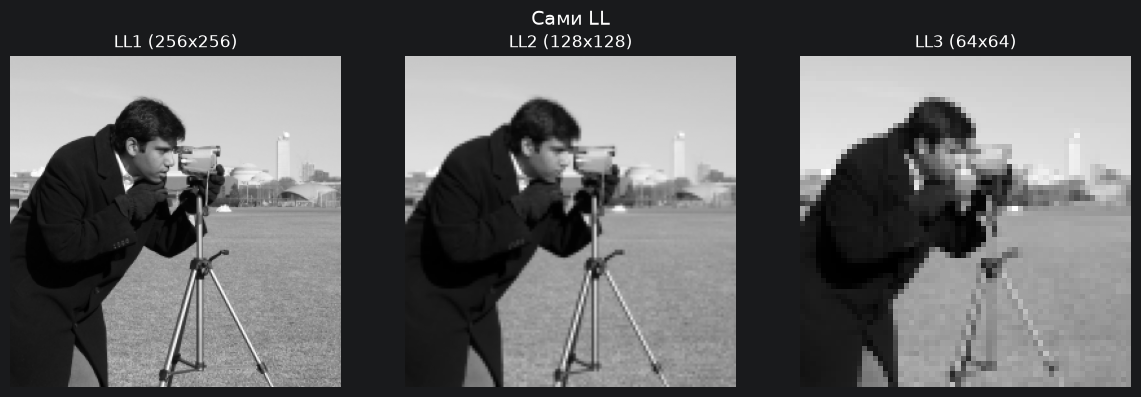

In [65]:
coeffs_st1 = np.zeros_like(image)
coeffs_st1[0:256, 0:256] = LL1
coeffs_st1[0:256, 256:512] = LH1
coeffs_st1[256:512, 0:256] = HL1
coeffs_st1[256:512, 256:512] = HH1

coeffs_st2 = coeffs_st1.copy()
coeffs_st2[0:128, 0:128] = LL2
coeffs_st2[0:128, 128:256] = LH2
coeffs_st2[128:256, 0:128] = HL2
coeffs_st2[128:256, 128:256] = HH2

coeffs_st3 = coeffs_st2.copy()
coeffs_st3[0:64, 0:64] = LL3
coeffs_st3[0:64, 64:128] = LH3
coeffs_st3[64:128, 0:64] = HL3
coeffs_st3[64:128, 64:128] = HH3

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(np.log1p(np.abs(coeffs_st1)), cmap="gray")
axes[0].set_title("1 уровень (256x256)")
axes[0].axis("off")

axes[1].imshow(np.log1p(np.abs(coeffs_st2)), cmap="gray")
axes[1].set_title("2 уровень (128x128)")
axes[1].axis("off")

axes[2].imshow(np.log1p(np.abs(coeffs_st3)), cmap="gray")
axes[2].set_title("3 уровень (64x64)")
axes[2].axis("off")

plt.suptitle("Карта коэффициентов", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(LL1, cmap="gray")
axes[0].set_title("LL1 (256x256)")
axes[0].axis("off")

axes[1].imshow(LL2, cmap="gray")
axes[1].set_title("LL2 (128x128)")
axes[1].axis("off")

axes[2].imshow(LL3, cmap="gray")
axes[2].set_title("LL3 (64x64)")
axes[2].axis("off")

plt.suptitle("Сами LL", fontsize=14)
plt.tight_layout()
plt.show()

# Восстановление и точная проверка (MSE / PSNR)

MSE: 0.000000000000
PSNR: inf dB


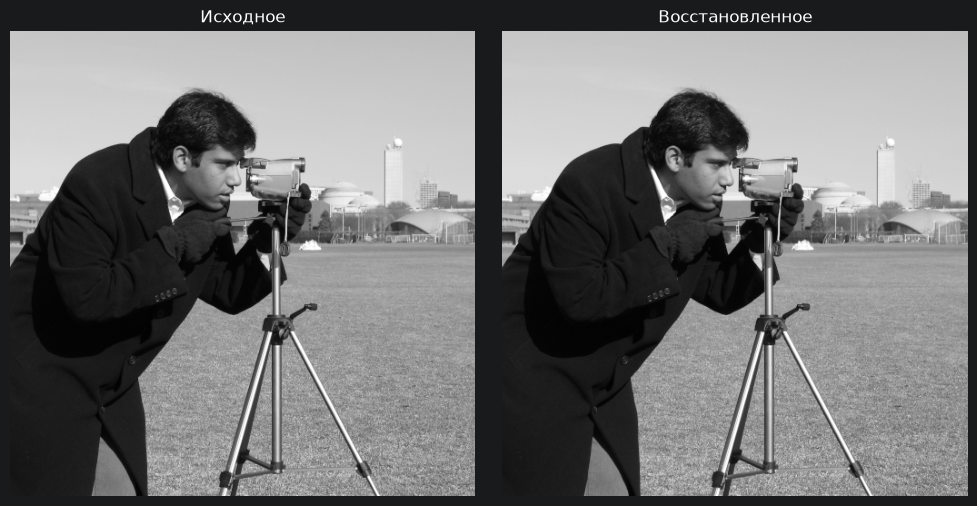

In [66]:
LL2_rec = ihaar2d_level(LL3, LH3, HL3, HH3)
LL1_rec = ihaar2d_level(LL2_rec, LH2, HL2, HH2)
img_rec = ihaar2d_level(LL1_rec, LH1, HL1, HH1)

mse_val = np.mean((image - img_rec) ** 2)
if mse_val < 1e-10:
    psnr_val = float('inf')
else:
    psnr_val = 10 * np.log10((255.0**2) / mse_val)

print(f'MSE: {mse_val:.12f}')
print(f'PSNR: {psnr_val} dB')

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Исходное')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_rec, cmap='gray')
plt.title('Восстановленное')
plt.axis('off')

plt.tight_layout()
plt.show()